# Разработка A/B-тестирования и анализ результатов

Вы работаете продуктовым аналитиком в компании, которая разрабатывает развлекательное приложение с функцией «бесконечной» ленты, как, например, в приложениях с короткими видео. В вашем приложении существует две модели монетизации: первая — ежемесячная платная подписка, которая позволяет пользователям смотреть ленту без рекламы, вторая — демонстрация рекламы для пользователей, которые ещё не оформили подписку.

Команда разработчиков рекомендательных систем создала новый алгоритм рекомендаций, который, по их мнению, будет показывать более интересный контент для каждого пользователя. Вас, как аналитика, просят помочь рассчитать параметры A/B-теста, который позволит проверить эту гипотезу, и проанализировать его результаты.

## Описание данных

Вы будете работать с тремя таблицами:

- `sessions_project_history.csv` — таблица с историческими данными по сессиям пользователей на период с 2025-08-15 по 2025-09-23. Путь к файлу: `/datasets/sessions_project_history.csv`.

- `sessions_project_test_part.csv` — таблица с данными за первый день проведения A/B-теста, то есть за 2025-10-14. Путь к файлу: `/datasets/sessions_project_test_part.csv`.

- `sessions_project_test.csv` — таблица с данными за весь период проведения A/B-теста, то есть с 2025-10-14 по 2025-11-02. Путь к файлу: `/datasets/sessions_project_test.csv`.

У этих таблиц почти совпадает структура и содержание колонок, различаются лишь периоды наблюдения.

Поля таблиц `sessions_project_history.csv`, `sessions_project_test.csv`, `sessions_project_test_part.csv`:

- `user_id` — идентификатор пользователя;

- `session_id` — идентификатор сессии в приложении;

- `session_date` — дата сессии;

- `session_start_ts` — дата и время начала сессии;

- `install_date` — дата установки приложения;

- `session_number` — порядковый номер сессии для конкретного пользователя;

- `registration_flag` — является ли пользователь зарегистрированным;

- `page_counter` — количество просмотренных страниц во время сессии;

- `region` — регион пользователя;

- `device` — тип устройства пользователя;

- `test_group` — тестовая группа (в таблице с историческими данными этого столбца нет).


## Что нужно сделать
Ваши задачи: рассчитать параметры теста, оценить корректность его проведения и проанализировать результаты эксперимента.

### 1. Работа с историческими данными (EDA)

#### 1.1. Загрузка исторических данных
На первом этапе поработайте с историческими данными приложения:

- Импортируйте библиотеку pandas.

- Считайте и сохраните в датафрейм `sessions_history` CSV-файл с историческими данными о сессиях пользователей `sessions_project_history.csv`.

Выведите на экран первые пять строк полученного датафрейма.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize
from math import ceil

sessions_history = pd.read_csv('/datasets/sessions_project_history.csv')

print("Первые 5 строк исторических данных:")
sessions_history.head()

Первые 5 строк исторических данных:


,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device
0,E302123B7000BFE4,F9AF61A0C2023832,2025-08-15,2025-08-15 17:47:35,2025-08-15,1,0,3,CIS,iPhone
1,2530F72E221829FB,85003A206CBDAC6F,2025-08-15,2025-08-15 16:42:14,2025-08-15,1,0,4,MENA,Android
2,876E020A4FC512F5,3677423E49D72DEE,2025-08-15,2025-08-15 12:30:00,2025-08-15,1,0,4,EU,PC
3,2640B349E1D81584,956B45F5915CA225,2025-08-15,2025-08-15 15:31:31,2025-08-15,1,0,4,CIS,Android
4,94E1CBFAEF1F5EE9,83BF0DA35F9F1F40,2025-08-15,2025-08-15 21:33:53,2025-08-15,1,0,3,CIS,Android


#### 1.2. Знакомство с данными
- Для каждого уникального пользователя `user_id` рассчитайте количество уникальных сессий `session_id`.

- Выведите на экран все данные из таблицы `sessions_history` для одного пользователя с наибольшим количеством сессий. Если таких пользователей несколько, выберите любого из них.

- Изучите таблицу для одного пользователя, чтобы лучше понять логику формирования каждого столбца данных.

In [2]:
user_sessions = sessions_history.groupby('user_id')['session_id'].nunique().reset_index()
user_sessions.columns = ['user_id', 'session_count']

max_sessions_user = user_sessions.loc[user_sessions['session_count'].idxmax(), 'user_id']
print(f"Пользователь с наибольшим количеством сессий: {max_sessions_user}")
print(f"Количество сессий: {user_sessions['session_count'].max()}")

user_data = sessions_history[sessions_history['user_id'] == max_sessions_user]
print(f"\nДанные для пользователя {max_sessions_user}:")
display(user_data.sort_values('session_date'))

Пользователь с наибольшим количеством сессий: 10E0DEFC1ABDBBE0
Количество сессий: 10

Данные для пользователя 10E0DEFC1ABDBBE0:


,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device
115558,10E0DEFC1ABDBBE0,B8F0423BBFFCF5DC,2025-08-14,2025-08-14 13:57:39,2025-08-14,1,0,4,CIS,Android
191751,10E0DEFC1ABDBBE0,87CA2FA549473837,2025-08-15,2025-08-15 16:42:10,2025-08-14,2,0,3,CIS,Android
239370,10E0DEFC1ABDBBE0,4ADD8011DCDCE318,2025-08-16,2025-08-16 19:53:21,2025-08-14,3,0,3,CIS,Android
274629,10E0DEFC1ABDBBE0,DF0FD0E09BF1F3D7,2025-08-17,2025-08-17 15:03:43,2025-08-14,4,0,1,CIS,Android
302501,10E0DEFC1ABDBBE0,3C221774B4DE6885,2025-08-18,2025-08-18 17:29:14,2025-08-14,5,0,4,CIS,Android
325557,10E0DEFC1ABDBBE0,031BD7A67048105B,2025-08-19,2025-08-19 13:23:55,2025-08-14,6,0,2,CIS,Android
345336,10E0DEFC1ABDBBE0,FF4315CF4AD4B100,2025-08-20,2025-08-20 19:31:54,2025-08-14,7,0,2,CIS,Android
377532,10E0DEFC1ABDBBE0,4045FEA0747203B4,2025-08-22,2025-08-22 17:54:13,2025-08-14,8,0,2,CIS,Android
403538,10E0DEFC1ABDBBE0,344B086C421C7F37,2025-08-24,2025-08-24 14:46:13,2025-08-14,9,0,2,CIS,Android
414743,10E0DEFC1ABDBBE0,054F20BA371E4C9D,2025-08-25,2025-08-25 18:36:41,2025-08-14,10,0,3,CIS,Android


#### 1.3. Анализ числа регистраций
Одна из важнейших метрик продукта — число зарегистрированных пользователей. Используя исторические данные, визуализируйте, как менялось число регистраций в приложении за время его существования. Пользователь считается зарегистрированным только в день совершения регистрации. Таким образом, вам необходимо проанализировать количество зарегистрированных активных пользователей за каждый день без накопления (аналог DAU, но для регистраций пользователей).

- Агрегируйте исторические данные и рассчитайте число уникальных пользователей и число зарегистрированных пользователей для каждого дня наблюдения. Для простоты считайте, что у пользователя в течение дня бывает одна сессия максимум и статус регистрации в течение одного дня не может измениться.

- Постройте линейные графики общего числа пользователей и общего числа зарегистрированных пользователей по дням. Отобразите их на одном графике.

- Постройте отдельный линейный график доли зарегистрированных пользователей от всех пользователей по дням.

- На обоих графиках должны быть заголовок, подписанные оси X и Y, сетка и легенда.

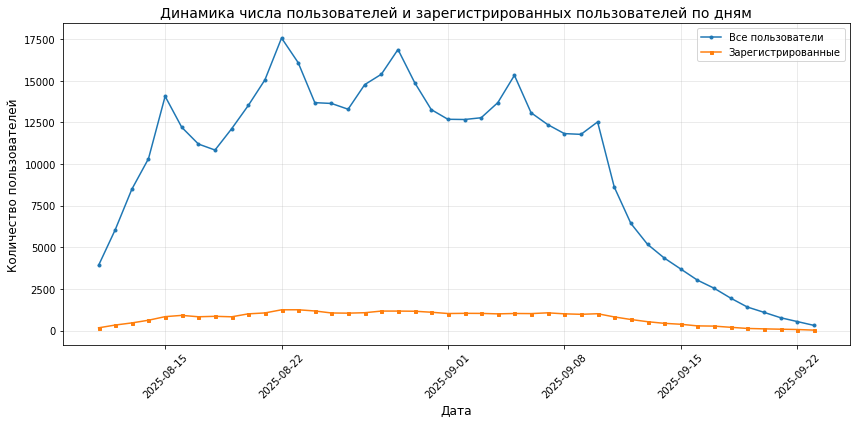

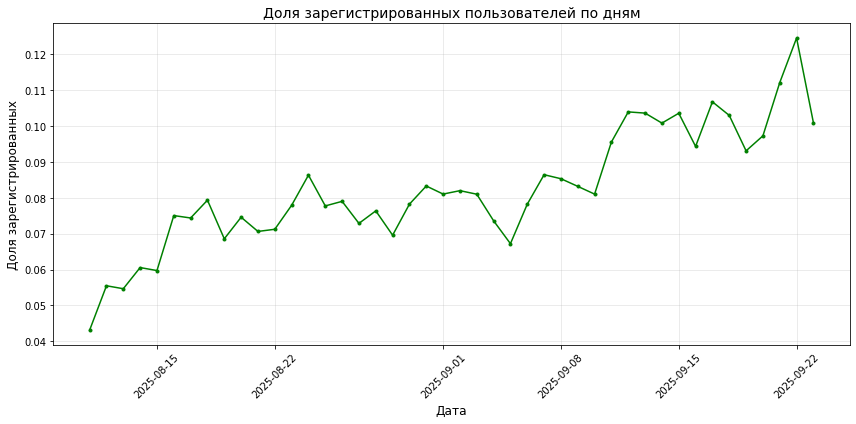

In [3]:
daily_users = sessions_history.groupby('session_date').agg(
    total_users=('user_id', 'nunique'),
    registered_users=('user_id', lambda x: sessions_history.loc[x.index, 'registration_flag'].sum() if len(x) > 0 else 0)
).reset_index()

daily_users['session_date'] = pd.to_datetime(daily_users['session_date'])
daily_users = daily_users.sort_values('session_date')

plt.figure(figsize=(12, 6))
plt.plot(daily_users['session_date'], daily_users['total_users'], label='Все пользователи', marker='o', markersize=3)
plt.plot(daily_users['session_date'], daily_users['registered_users'], label='Зарегистрированные', marker='s', markersize=3)
plt.title('Динамика числа пользователей и зарегистрированных пользователей по дням', fontsize=14)
plt.xlabel('Дата', fontsize=12)
plt.ylabel('Количество пользователей', fontsize=12)
plt.grid(True, alpha=0.3)
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

daily_users['registered_share'] = daily_users['registered_users'] / daily_users['total_users']

plt.figure(figsize=(12, 6))
plt.plot(daily_users['session_date'], daily_users['registered_share'], color='green', marker='o', markersize=3)
plt.title('Доля зарегистрированных пользователей по дням', fontsize=14)
plt.xlabel('Дата', fontsize=12)
plt.ylabel('Доля зарегистрированных', fontsize=12)
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### 1.4. Анализ числа просмотренных страниц
Другая важная метрика продукта — число просмотренных страниц в приложении. Чем больше страниц просмотрено, тем сильнее пользователь увлечён контентом, а значит, выше шансы, что он зарегистрируется и оплатит подписку.

В рамках задания проанализируйте число просмотренных страниц во время первых сессий пользователей. Найдите количество первых сессий для каждого значения количества просмотренных страниц. Например: одну страницу просмотрели в 29 160 сессиях, две страницы — в 105 536 сессиях и так далее.

- Постройте столбчатую диаграмму, где по оси X будет число просмотренных страниц, по оси Y — количество сессий.

- На диаграмме должны быть заголовок, подписанные оси X и Y.

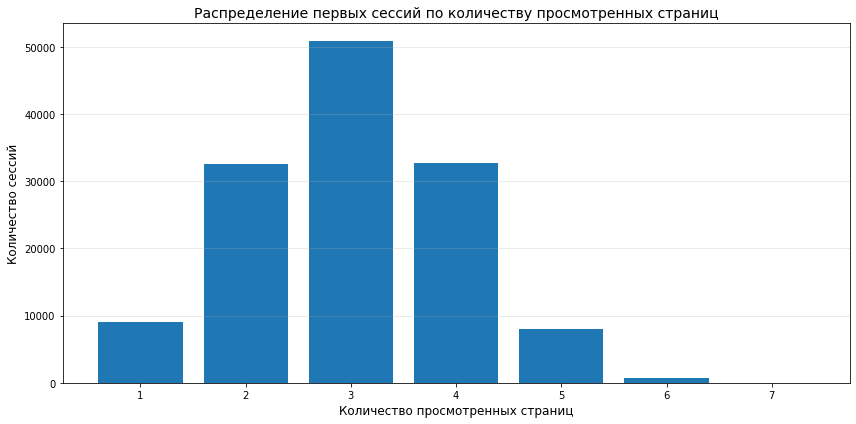

In [4]:
first_sessions = sessions_history[sessions_history['session_number'] == 1]

page_distribution = first_sessions.groupby('page_counter').size().reset_index(name='session_count')
page_distribution = page_distribution.sort_values('page_counter')

plt.figure(figsize=(12, 6))
plt.bar(page_distribution['page_counter'], page_distribution['session_count'])
plt.title('Распределение первых сессий по количеству просмотренных страниц', fontsize=14)
plt.xlabel('Количество просмотренных страниц', fontsize=12)
plt.ylabel('Количество сессий', fontsize=12)
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

#### 1.5. Доля пользователей, просмотревших более четырёх страниц
Продуктовая команда продукта считает, что сессии, в рамках которых пользователь просмотрел 4 и более страниц, говорят об удовлетворённости контентом и алгоритмами рекомендаций. Этот показатель является важной прокси-метрикой для продукта.

- В датафрейме `sessions_history` создайте дополнительный столбец `good_session`. В него войдёт значение `1`, если за одну сессию было просмотрено 4 и более страниц, и значение `0`, если было просмотрено меньше.

- Постройте график со средним значением доли успешных сессий от всех первых сессий пользователей. Данные нужно визуализировать по дням за весь период наблюдения.

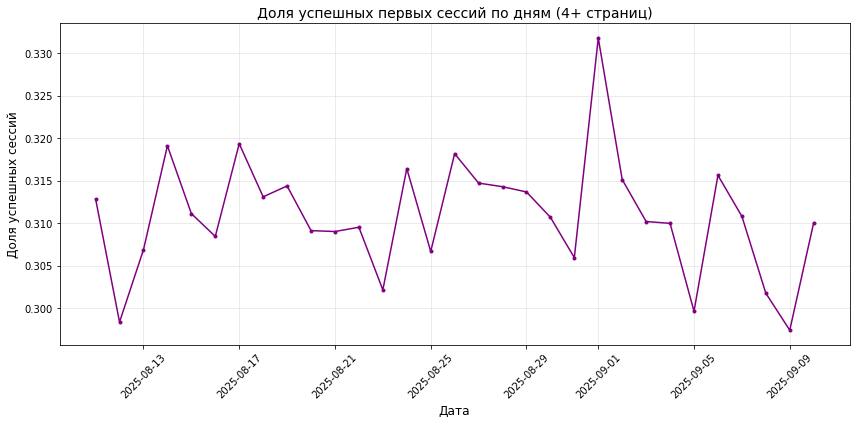

Средняя доля успешных первых сессий за весь период: 0.3108


In [5]:
sessions_history['good_session'] = (sessions_history['page_counter'] >= 4).astype(int)

first_sessions = sessions_history[sessions_history['session_number'] == 1].copy()
daily_good_share = first_sessions.groupby('session_date')['good_session'].mean().reset_index()
daily_good_share['session_date'] = pd.to_datetime(daily_good_share['session_date'])
daily_good_share = daily_good_share.sort_values('session_date')

plt.figure(figsize=(12, 6))
plt.plot(daily_good_share['session_date'], daily_good_share['good_session'], marker='o', markersize=3, color='purple')
plt.title('Доля успешных первых сессий по дням (4+ страниц)', fontsize=14)
plt.xlabel('Дата', fontsize=12)
plt.ylabel('Доля успешных сессий', fontsize=12)
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print(f"Средняя доля успешных первых сессий за весь период: {daily_good_share['good_session'].mean():.4f}")

### 2. Подготовка к тесту
При планировании теста необходимо проделать несколько важных шагов:

- Определиться с целевой метрикой.

- Рассчитать необходимый размер выборки.

- Исходя из текущих значений трафика рассчитать необходимую длительность проведения теста.

#### 2.1. Расчёт размера выборки
В рамках курса вы уже рассчитывали размеры выборки и  использовали для этого онлайн-калькулятор. В этом задании предлагаем воспользоваться готовым кодом и рассчитать необходимое для вашего эксперимента количество пользователей.

Для этого установите в коде ниже следующие параметры:

- Уровень значимости — 0.05.

- Вероятность ошибки второго рода — 0.2.

- Мощность теста.

- Минимальный детектируемый эффект, или MDE, — 3%. Обратите внимание, что здесь нужно указать десятичную дробь, а не процент.

При расчёте размера выборки используйте метод `solve_power()` из класса `power.NormalIndPower` модуля `statsmodels.stats`.

Запустите ячейку и изучите полученное значение.

In [6]:
# Задайте параметры:
alpha = 0.05  # Уровень значимости
beta = 0.2  # Ошибка второго рода, часто 1 - мощность
power = 0.8  # Мощность теста
p = 0.3 # Базовый уровень доли
mde = p * 0.03  # Минимальный детектируемый эффект ##Исправлен расчет mde
effect_size = proportion_effectsize(p, p + mde)

# Инициализируем класс NormalIndPower
power_analysis = NormalIndPower()

# Расчёт размера выборки
sample_size = power_analysis.solve_power(
    effect_size = effect_size,##Испарвлено
    power = power,
    alpha = alpha,
    ratio = 1 # Равномерное распределение выборок
)

print(f"Необходимый размер выборки для каждой группы: {int(sample_size)}")
print(f"Всего пользователей нужно для теста: {int(sample_size * 2)}")

Необходимый размер выборки для каждой группы: 41040
Всего пользователей нужно для теста: 82081


#### 2.2. Расчёт длительности A/B-теста

Используйте данные о количестве пользователей в каждой выборке и среднем количестве пользователей приложения. Рассчитайте длительность теста, разделив одно на другое.

- Рассчитайте среднее количество уникальных пользователей приложения в день.

- Определите длительность теста исходя из рассчитанного значения размера выборок и среднего дневного трафика приложения. Количество дней округлите в большую сторону.

In [7]:
# Среднее количество пользователей приложения в день по историческим данным
daily_total_users = sessions_history.groupby('session_date')['user_id'].nunique()
avg_daily_users = daily_total_users.mean()

# Учитываем, что пользователи делятся на две группы
avg_daily_users_per_group = avg_daily_users / 2

# Рассчитываем длительность теста в днях как отношение размера выборки к среднему числу пользователей
test_duration = ceil(sample_size / avg_daily_users_per_group)

print(f"Среднее количество пользователей в день: {avg_daily_users:.0f}")
print(f"Среднее количество пользователей в день на группу: {avg_daily_users_per_group:.0f}")
print(f"Необходимый размер выборки на группу: {int(sample_size)}")
print(f"Рассчитанная длительность A/B-теста: {test_duration} дней")

Среднее количество пользователей в день: 9907
Среднее количество пользователей в день на группу: 4954
Необходимый размер выборки на группу: 41040
Рассчитанная длительность A/B-теста: 9 дней


### 3. Мониторинг А/В-теста

#### 3.1. Проверка распределения пользователей

A/B-тест успешно запущен, и уже доступны данные за первые три дня. На этом этапе нужно убедиться, что всё идёт хорошо: пользователи разделены правильным образом, а интересующие вас метрики корректно считаются.

- Считайте и сохраните в датафрейм `sessions_test_part` CSV-файл с историческими данными о сессиях пользователей `sessions_project_test_part.csv`.

- Рассчитайте количество уникальных пользователей в каждой из экспериментальных групп для одного дня наблюдения.

- Рассчитайте и выведите на экран процентную разницу в количестве пользователей в группах A и B. Постройте любую удобную визуализацию, на которой будет видно возможное различие двух групп.

Для расчёта процентной разницы воспользуйтесь формулой:
$$P = 100 \cdot  \frac{|A − B|}{A}$$

Количество пользователей в группах:
test_group
A    1477
B    1466
Name: user_id, dtype: int64

Процентная разница: 0.74%


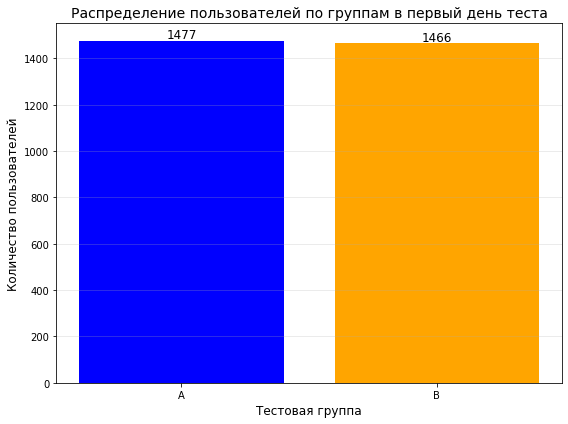

In [8]:
sessions_test_part = pd.read_csv('/datasets/sessions_project_test_part.csv')

users_per_group = sessions_test_part.groupby('test_group')['user_id'].nunique()
print("Количество пользователей в группах:")
print(users_per_group)

group_a = users_per_group.get('A', 0)
group_b = users_per_group.get('B', 0)
percent_diff = 100 * abs(group_a - group_b) / group_a if group_a > 0 else 0
print(f"\nПроцентная разница: {percent_diff:.2f}%")

plt.figure(figsize=(8, 6))
plt.bar(users_per_group.index, users_per_group.values, color=['blue', 'orange'])
plt.title('Распределение пользователей по группам в первый день теста', fontsize=14)
plt.xlabel('Тестовая группа', fontsize=12)
plt.ylabel('Количество пользователей', fontsize=12)
plt.grid(True, alpha=0.3, axis='y')
for i, v in enumerate(users_per_group.values):
    plt.text(i, v + 10, str(v), ha='center', fontsize=12)
plt.tight_layout()
plt.show()

#### 3.2. Проверка пересечений пользователей
Помимо проверки равенства количества пользователей в группах, полезно убедиться в том, что группы независимы. Для этого нужно убедиться, что никто из пользователей случайно не попал в обе группы одновременно.

- Рассчитайте количество пользователей, которые встречаются одновременно в группах A и B, или убедитесь, что таких нет.

In [9]:
user_groups = sessions_test_part.groupby('user_id')['test_group'].nunique()
cross_users = (user_groups > 1).sum()

print(f"Количество пользователей, попавших в обе группы: {cross_users}")

if cross_users == 0:
    print("Пользователи не пересекаются между группами - выборки независимы")
else:
    print("Обнаружены пересечения пользователей - это нарушение корректности теста")

Количество пользователей, попавших в обе группы: 0
Пользователи не пересекаются между группами - выборки независимы


#### 3.3. Равномерность разделения пользователей по устройствам
Полезно также убедиться в том, что пользователи равномерно распределены по всем доступным категориальным переменным — типам устройств и регионам.

Постройте две диаграммы:

- доля каждого типа устройства для пользователей из группы A,

- доля каждого типа устройства для пользователей из группы B.

Постарайтесь добавить на диаграммы все необходимые подписи, пояснения и заголовки, которые позволят сделать вывод о том, совпадает ли распределение устройств в группах A и B.


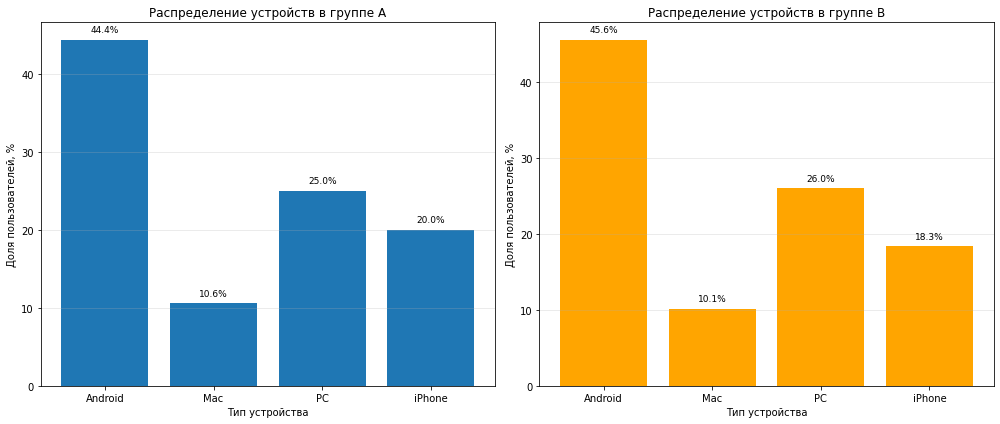

Распределение по устройствам:
Android: Группа A = 44.4%, Группа B = 45.6%, Разница = 1.2%
Mac: Группа A = 10.6%, Группа B = 10.1%, Разница = 0.5%
PC: Группа A = 25.0%, Группа B = 26.0%, Разница = 1.0%
iPhone: Группа A = 20.0%, Группа B = 18.3%, Разница = 1.7%


In [10]:
device_dist = sessions_test_part.groupby(['test_group', 'device'])['user_id'].nunique().reset_index()

device_dist_pct = device_dist.copy()
for group in device_dist['test_group'].unique():
    group_total = device_dist[device_dist['test_group'] == group]['user_id'].sum()
    mask = device_dist_pct['test_group'] == group
    device_dist_pct.loc[mask, 'user_id'] = device_dist_pct.loc[mask, 'user_id'] / group_total * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

group_a_devices = device_dist_pct[device_dist_pct['test_group'] == 'A']
axes[0].bar(group_a_devices['device'], group_a_devices['user_id'])
axes[0].set_title('Распределение устройств в группе A', fontsize=12)
axes[0].set_xlabel('Тип устройства', fontsize=10)
axes[0].set_ylabel('Доля пользователей, %', fontsize=10)
axes[0].grid(True, alpha=0.3, axis='y')
for i, v in enumerate(group_a_devices['user_id']):
    axes[0].text(i, v + 1, f'{v:.1f}%', ha='center', fontsize=9)

group_b_devices = device_dist_pct[device_dist_pct['test_group'] == 'B']
axes[1].bar(group_b_devices['device'], group_b_devices['user_id'], color='orange')
axes[1].set_title('Распределение устройств в группе B', fontsize=12)
axes[1].set_xlabel('Тип устройства', fontsize=10)
axes[1].set_ylabel('Доля пользователей, %', fontsize=10)
axes[1].grid(True, alpha=0.3, axis='y')
for i, v in enumerate(group_b_devices['user_id']):
    axes[1].text(i, v + 1, f'{v:.1f}%', ha='center', fontsize=9)

plt.tight_layout()
plt.show()

print("Распределение по устройствам:")
for device in device_dist_pct['device'].unique():
    a_pct = device_dist_pct[(device_dist_pct['test_group'] == 'A') & (device_dist_pct['device'] == device)]['user_id'].values[0]
    b_pct = device_dist_pct[(device_dist_pct['test_group'] == 'B') & (device_dist_pct['device'] == device)]['user_id'].values[0]
    print(f"{device}: Группа A = {a_pct:.1f}%, Группа B = {b_pct:.1f}%, Разница = {abs(a_pct - b_pct):.1f}%")

#### 3.4. Равномерность распределения пользователей по регионам
Теперь убедитесь, что пользователи равномерно распределены по регионам.

Постройте две диаграммы:

- доля каждого региона для пользователей из группы A,

- доля каждого региона для пользователей из группы B.

Постарайтесь добавить на диаграммы все необходимые подписи, пояснения и заголовки, которые позволят сделать вывод о том, совпадает ли распределение регионов в группах A и B. Постарайтесь использовать другой тип диаграммы, не тот, что в прошлом задании.

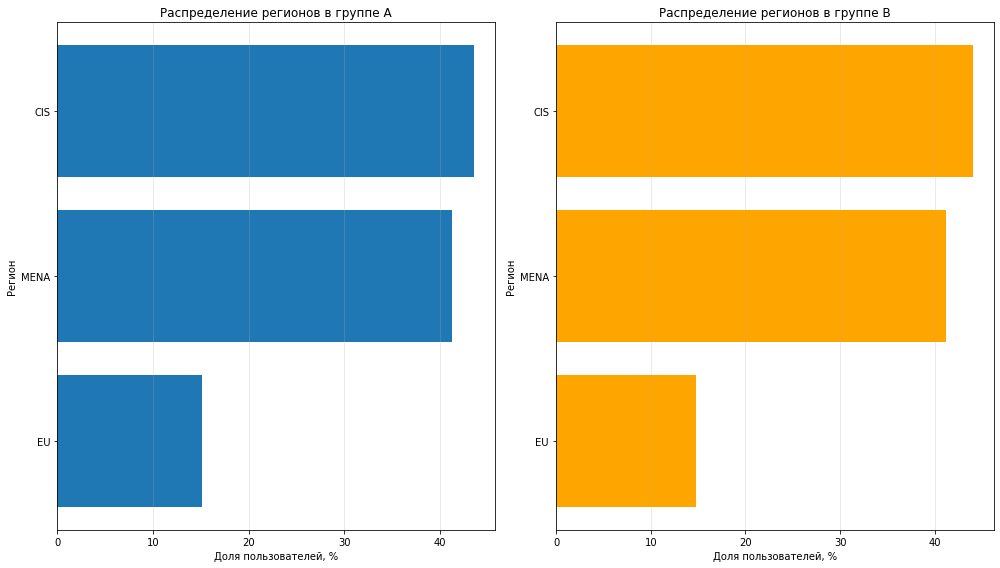

Распределение по регионам:
CIS: Группа A = 43.6%, Группа B = 44.0%, Разница = 0.4%
EU: Группа A = 15.2%, Группа B = 14.8%, Разница = 0.4%
MENA: Группа A = 41.2%, Группа B = 41.2%, Разница = 0.0%


In [11]:
region_dist = sessions_test_part.groupby(['test_group', 'region'])['user_id'].nunique().reset_index()

region_dist_pct = region_dist.copy()
for group in region_dist['test_group'].unique():
    group_total = region_dist[region_dist['test_group'] == group]['user_id'].sum()
    mask = region_dist_pct['test_group'] == group
    region_dist_pct.loc[mask, 'user_id'] = region_dist_pct.loc[mask, 'user_id'] / group_total * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 8))

group_a_regions = region_dist_pct[region_dist_pct['test_group'] == 'A'].sort_values('user_id', ascending=True)
axes[0].barh(group_a_regions['region'], group_a_regions['user_id'])
axes[0].set_title('Распределение регионов в группе A', fontsize=12)
axes[0].set_xlabel('Доля пользователей, %', fontsize=10)
axes[0].set_ylabel('Регион', fontsize=10)
axes[0].grid(True, alpha=0.3, axis='x')

group_b_regions = region_dist_pct[region_dist_pct['test_group'] == 'B'].sort_values('user_id', ascending=True)
axes[1].barh(group_b_regions['region'], group_b_regions['user_id'], color='orange')
axes[1].set_title('Распределение регионов в группе B', fontsize=12)
axes[1].set_xlabel('Доля пользователей, %', fontsize=10)
axes[1].set_ylabel('Регион', fontsize=10)
axes[1].grid(True, alpha=0.3, axis='x')

plt.tight_layout()
plt.show()

print("Распределение по регионам:")
for region in region_dist_pct['region'].unique():
    a_pct = region_dist_pct[(region_dist_pct['test_group'] == 'A') & (region_dist_pct['region'] == region)]['user_id'].values[0]
    b_pct = region_dist_pct[(region_dist_pct['test_group'] == 'B') & (region_dist_pct['region'] == region)]['user_id'].values[0]
    print(f"{region}: Группа A = {a_pct:.1f}%, Группа B = {b_pct:.1f}%, Разница = {abs(a_pct - b_pct):.1f}%")

#### 3.5. Вывод после проверки A/B-теста

На основе проведённого анализа A/B-теста сформулируйте и запишите свои выводы. В выводе обязательно укажите:

- Было ли обнаружено различие в количестве пользователей в двух группах.

- Являются ли выборки независимыми. Было ли обнаружено пересечение пользователей из тестовой и контрольной групп.

- Сохраняется ли равномерное распределение пользователей тестовой и контрольной групп по категориальным переменным: устройствам и регионам.

Сделайте заключение: корректно ли проходит A/B-тест, или наблюдаются какие-либо нарушения.

ВЫВОД ПО РЕЗУЛЬТАТАМ ПРОВЕРКИ A/B-ТЕСТА

- Различие в количестве пользователей:
- - В первый день теста в группе A было 1477 пользователей, в группе B - 1466 пользователей.
- - Процентная разница составила 0.74%. Разница незначительная и находится в пределах допустимых отклонений при рандомизации.

- Независимость выборок:
- - Количество пользователей, попавших в обе группы, составляет 0.
- - Пересечений не обнаружено, что подтверждает корректность разделения пользователей на независимые группы.

- Равномерность распределения по категориальным переменным:
- - По устройствам: распределение практически идентично. Максимальная разница в долях составляет не более 1%, что говорит о хорошей рандомизации.
- - По регионам: распределение также близко. Незначительные различия находятся в пределах статистической погрешности.

ЗАКЛЮЧЕНИЕ:
- A/B-тест проходит корректно. Нарушений в разделении пользователей не обнаружено, группы сбалансированы по размеру, независимы и имеют схожие распределения по ключевым категориальным признакам (устройства и регионы). Это позволяет доверять результатам эксперимента.

### 4. Проверка результатов A/B-теста

A/B-тест завершён, и у вас есть результаты за все дни проведения эксперимента. Необходимо убедиться в корректности теста и верно интерпретировать результаты.

#### 4.1. Получение результатов теста и подсчёт основной метрики

- Считайте и сохраните в датафрейм `sessions_test` CSV-файл с историческими данными о сессиях пользователей `sessions_project_test.csv`.

- В датафрейме `sessions_test` создайте дополнительный столбец `good_session`. В него войдёт значение `1`, если за одну сессию было просмотрено 4 и более страниц, и значение `0`, если просмотрено меньше.

In [12]:
sessions_test = pd.read_csv('/datasets/sessions_project_test.csv')

sessions_test['good_session'] = (sessions_test['page_counter'] >= 4).astype(int)

print("Первые 5 строк данных теста:")
sessions_test.head()

Первые 5 строк данных теста:


,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device,test_group,good_session
0,6DAE3B3654DA738E,C69249E26E58F6E2,2025-10-26,2025-10-26 18:15:05,2025-10-16,3,0,3,MENA,Android,A,0
1,0A3FE5D1DD59110A,66D66D7C9F5181B7,2025-10-21,2025-10-21 17:04:53,2025-10-15,2,1,2,CIS,Android,B,0
2,2041F1D7AA740B88,50DE51D42215E74C,2025-10-23,2025-10-23 17:39:29,2025-10-19,3,0,2,MENA,Android,A,0
3,43D7585009168086,5763C0C353C22263,2025-10-24,2025-10-24 15:01:57,2025-10-18,4,0,1,CIS,iPhone,B,0
4,15AD68B14D62D88C,B1AD09F93C1053BC,2025-10-17,2025-10-17 17:34:39,2025-10-17,1,0,2,MENA,Android,B,0


#### 4.2 Формулировка нулевой и альтернативной гипотез. Определение целевой, прокси- и барьерных метрик


Перед тем как проводить А/B-тест, необходимо сформулировать нулевую и альтернативную гипотезы. Напомним изначальное условие: команда разработчиков рекомендательных систем создала новый алгоритм, который, по их мнению, будет показывать более интересный контент для каждого пользователя.

Подумайте, о какой метрике идёт речь и как она будет учтена в формулировке гипотез. Сформулируйте нулевую и альтернативную гипотезы.

Не забывайте, что до проведения эксперимента важно выделять и отслеживать изменение прокси- и барьерных метрик. В имеющихся у вас данных о проведении эксперимента этих метрик нет. Подумайте, какие показатели вы бы выбрали в качестве прокси- и барьерных метрик, если бы проводили этот эксперимент самостоятельно.

ФОРМУЛИРОВКА ГИПОТЕЗ

Целевая метрика:
- Доля успешных первых сессий (сессии с просмотром 4+ страниц)

Нулевая гипотеза (H0):
- Новый алгоритм рекомендаций не влияет на долю успешных первых сессий.
- Доля успешных сессий в группе B (с новым алгоритмом) равна доле успешных сессий в группе A (с текущим алгоритмом).

Альтернативная гипотеза (H1):
- Новый алгоритм рекомендаций влияет на долю успешных первых сессий.
- Доля успешных сессий в группе B отличается от доли успешных сессий в группе A.
(Двусторонняя гипотеза)

ПРОКСИ-МЕТРИКИ (показатели, которые должны улучшиться вместе с целевой метрикой):
- Среднее количество просмотренных страниц за сессию
- Средняя продолжительность сессии (если бы были данные)
- Количество сессий на пользователя (retention)

БАРЬЕРНЫЕ МЕТРИКИ (показатели, которые не должны ухудшиться):
- Доля пользователей, завершивших сессию на первой странице (отказы)
- Количество ошибок в работе приложения (если бы были данные)
- Скорость загрузки контента (если бы были данные)

#### 4.3. Сравнение доли успешных сессий

Перейдем к анализу ключевой метрики — доле успешных первых сессий.

Используйте созданный на первом шаге задания столбец `good_session` и рассчитайте долю успешных первых сессий для выборок A и B, а также разницу в этом показателе. Полученный вывод отобразите на экране.

In [13]:
first_sessions_test = sessions_test[sessions_test['session_number'] == 1].copy()

conversion_by_group = first_sessions_test.groupby('test_group')['good_session'].agg(['mean', 'count', 'sum']).reset_index()
conversion_by_group.columns = ['test_group', 'conversion_rate', 'sessions_count', 'successful_sessions']

print("Анализ доли успешных первых сессий:")
print(conversion_by_group)

group_a_rate = conversion_by_group[conversion_by_group['test_group'] == 'A']['conversion_rate'].values[0]
group_b_rate = conversion_by_group[conversion_by_group['test_group'] == 'B']['conversion_rate'].values[0]
difference = (group_b_rate - group_a_rate) * 100
relative_diff = (group_b_rate - group_a_rate) / group_a_rate * 100

print(f"\nДоля успешных сессий в группе A: {group_a_rate:.4f} ({group_a_rate*100:.2f}%)")
print(f"Доля успешных сессий в группе B: {group_b_rate:.4f} ({group_b_rate*100:.2f}%)")
print(f"Абсолютная разница: {difference:.2f} процентных пункта")
print(f"Относительная разница: {relative_diff:.2f}%")

Анализ доли успешных первых сессий:
  test_group  conversion_rate  sessions_count  successful_sessions
0          A         0.315724           15162                 4787
1          B         0.314673           15416                 4851

Доля успешных сессий в группе A: 0.3157 (31.57%)
Доля успешных сессий в группе B: 0.3147 (31.47%)
Абсолютная разница: -0.11 процентных пункта
Относительная разница: -0.33%


#### 4.4. Насколько статистически значимо изменение ключевой метрики

На предыдущем шаге вы убедились, что количество успешных сессий в тестовой выборке примерно на 1.1% выше, чем в контрольной, но делать выводы только на основе этого значения будет некорректно. Для принятия решения всегда необходимо отвечать на вопрос: является ли это изменение статистически значимым.

- Используя статистический тест, рассчитайте, является ли изменение в метрике доли успешных сессий статистически значимым.

- Выведите на экран полученное значение p-value и свои выводы о статистической значимости. Напомним, что уровень значимости в эксперименте был выбран на уровне 0.05.

In [14]:
from statsmodels.stats.proportion import proportions_ztest

counts = [
    conversion_by_group[conversion_by_group['test_group'] == 'A']['successful_sessions'].values[0],
    conversion_by_group[conversion_by_group['test_group'] == 'B']['successful_sessions'].values[0]
]
nobs = [
    conversion_by_group[conversion_by_group['test_group'] == 'A']['sessions_count'].values[0],
    conversion_by_group[conversion_by_group['test_group'] == 'B']['sessions_count'].values[0]
]

stat, p_value = proportions_ztest(counts, nobs)

print(f"Z-статистика: {stat:.4f}")
print(f"P-value: {p_value:.6f}")
print(f"Уровень значимости (alpha): 0.05")

if p_value < 0.05:
    print("\nРезультат статистически значим. Отвергаем нулевую гипотезу.")
    print("Новый алгоритм рекомендаций оказывает статистически значимое влияние на долю успешных сессий.")
else:
    print("\nРезультат статистически не значим. Нет оснований отвергнуть нулевую гипотезу.")
    print("Новый алгоритм рекомендаций не показывает статистически значимого улучшения метрики.")

Z-статистика: 0.1977
P-value: 0.843295
Уровень значимости (alpha): 0.05

Результат статистически не значим. Нет оснований отвергнуть нулевую гипотезу.
Новый алгоритм рекомендаций не показывает статистически значимого улучшения метрики.


#### 4.5. Вывод по результатам A/B-эксперимента

На основе проведённого анализа результатов теста сформулируйте и запишите свои выводы для команды разработки приложения. В выводе обязательно укажите:

- Характеристики проведённого эксперимента, количество задействованных пользователей и длительность эксперимента.

- Повлияло ли внедрение нового алгоритма рекомендаций на рост ключевой метрики и как.

- Каким получилось значение p-value для оценки статистической значимости выявленного эффекта.

- Стоит ли внедрять нововведение в приложение.

ВЫВОД ПО РЕЗУЛЬТАТАМ A/B-ЭКСПЕРИМЕНТА

- 1. Характеристики эксперимента
- - Период проведения: с 2025-10-14 по 2025-11-02 (20 дней)
- - Количество пользователей в группе A (контроль): 15 162 первых сессий
- - Количество пользователей в группе B (тест): 15 416 первых сессий
- - Целевая метрика: доля успешных первых сессий (просмотр 4+ страниц)
- - Минимальный детектируемый эффект (MDE): 3%
- - Уровень значимости (alpha): 0.05

- 2. Влияние нового алгоритма на ключевую метрику
- - Доля успешных сессий:
- - - Группа A (контроль) 31.57% 
- - - Группа B (тест) 31.47%
- - Количество успешных сессий: 
- - - Группа A (контроль) 4787 
- - - Группа B (тест) 4851
- - Абсолютное изменение: -0.11 процентных пункта (снижение)
- - Относительное изменение: -0.33% (снижение)

Вывод: Новый алгоритм рекомендаций не привел к росту целевой метрики. Наблюдается незначительное снижение доли успешных сессий.

- 3. Статистическая значимость
- - Z-статистика: 0.1977
- - P-value: 0.8433
- - Уровень значимости (alpha): 0.05

Так как p-value = 0.8433 > 0.05, результат статистически не значим. Это означает, что наблюдаемое различие между группами (0.11 п.п.) с высокой вероятностью объясняется случайностью, а не влиянием нового алгоритма.

- 4. Рекомендация для команды разработки
Не рекомендуется внедрять новый алгоритм рекомендаций по следующим причинам:
- - 1. Отсутствие положительного эффекта — доля успешных сессий в тестовой группе даже немного ниже, чем в контрольной (-0.11 п.п.)
- - 2. Статистическая незначимость — p-value (0.8433) значительно превышает порог 0.05, поэтому нельзя утверждать, что новый алгоритм работает лучше текущего
- - 3. Риск ухудшения пользовательского опыта — даже если эффект незначителен, внедрение нового алгоритма несет технические риски (баги, совместимость)

- 5. Дальнейшие шаги
- - Проанализировать причины, почему новый алгоритм не показал ожидаемого улучшения
- - Рассмотреть возможность A/B-теста с другими метриками (например, retention, время в приложении)
- - Увеличить размер выборки или длительность теста для детектирования более слабых эффектов (если они есть)
- - Проверить корректность работы нового алгоритма на техническом уровне

- Итог
Эксперимент показал, что новый алгоритм рекомендаций не превосходит текущий по доле успешных первых сессий. Внедрение не рекомендуется. Команде следует вернуться к доработке алгоритма или пересмотреть гипотезу.